# Kazakh Profanity Detection: end-to-end notebook

**Task:** read one Kazakh product review or comment and predict **1 = contains profanity (мат)** or **0 = clean**, with a probability.

```
1 Load data → 2 Clean → 3 Normalise → 4 Label → 5 Split → 6 Features → 7 Train (+validation) → 8 Threshold
→ 9 Test → 10 Interpret → 11 Errors → 12 Challenge set → 13 Save model → 14 Predict your own comment
```

*Run all: about 1-2 minutes on a laptop or in a fresh Google Colab runtime. Seed 42 everywhere.*

Two helpers are imported from the `kzprofanity/` package instead of being defined here:
* `canonical()`, the text normaliser. The saved model calls it inside its pipeline, and a function defined in a notebook
  cannot be loaded back by `predict.py`.
* the lexicon (45 regex rules), the **labeling tool**. It only proposes labels and is never a model feature.

> Privacy: the notebook prints only **counts and hand-written examples**, never real review texts (they can contain names).

## 0. Setup

In [1]:
import os, sys, io, zipfile, json, subprocess
from pathlib import Path

if 'google.colab' in sys.modules and not Path('kzprofanity').exists():      # fresh Colab runtime
    subprocess.run(['git', 'clone', '-q', 'https://github.com/DzoTo/DL-bonus-task.git', 'repo'], check=True)
    os.chdir('repo')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, str(Path.cwd()))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests, yaml, joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve, roc_auc_score, average_precision_score,
                             accuracy_score, classification_report)
from IPython.display import display, Markdown

from kzprofanity.text import canonical, scrub_pii, dedupe_key, letter_count   # normalisation + PII helpers
from kzprofanity.lexicon import find_hits, lexicon_label, predict_lexicon       # labeling tool

CFG = yaml.safe_load(open('config.yaml', encoding='utf-8'))   # every setting lives here
SEED = CFG['seed']
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 70)
plt.rcParams['figure.dpi'] = 110
print('seed:', SEED, '| split:', CFG['split'], '| grid C:', CFG['model']['search']['C'])

seed: 42 | split: {'train': 0.7, 'val': 0.15, 'test': 0.15} | grid C: [0.1, 1.0, 10.0, 30.0, 100.0]


## 1. Load the dataset: KazSAnDRA
[KazSAnDRA](https://github.com/IS2AI/KazSAnDRA) (ISSAI, CC BY 4.0) contains 175k real Kazakh reviews from app stores, online markets,
maps and bookstores, with 1-5 star ratings. It is labeled for **sentiment**, not profanity, so we keep the text and build our own labels.

175,158 reviews


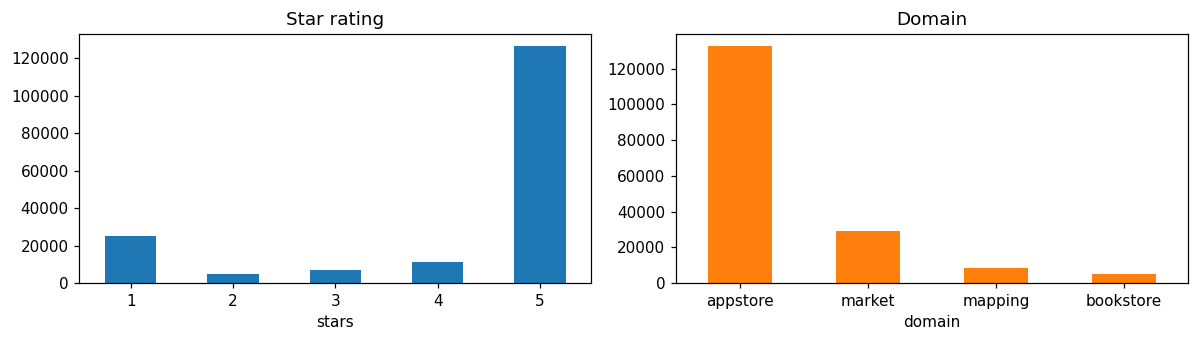

In [2]:
raw_dir = Path(CFG['paths']['raw_dir']); raw_dir.mkdir(parents=True, exist_ok=True)
frames = []
for name in CFG['source']['files']:
    zpath = raw_dir / f'{name}.zip'
    if not zpath.exists():                                   # download once, then reuse
        zpath.write_bytes(requests.get(f"{CFG['source']['base_url']}/{name}.zip", timeout=120).content)
    with zipfile.ZipFile(zpath) as z:
        frames.append(pd.read_csv(io.BytesIO(z.read(f'{name}.csv'))))
raw = pd.concat(frames, ignore_index=True)
df = pd.DataFrame({'id': raw.custom_id.astype(str), 'text': raw.text.astype(str),
                   'stars': raw.label.astype(int) + 1,       # KazSAnDRA labels 0..4 -> stars 1..5
                   'domain': raw.domain.astype(str)})
print(f'{len(df):,} reviews')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
df.stars.value_counts().sort_index().plot.bar(ax=ax[0], rot=0, title='Star rating'); ax[0].set_xlabel('stars')
df.domain.value_counts().plot.bar(ax=ax[1], rot=0, title='Domain', color='tab:orange')
plt.tight_layout(); plt.show()

## 2. Clean: personal data, very short comments, duplicates
* Links, e-mails, phone numbers and @usernames → `<URL>`, `<EMAIL>`, `<PHONE>`, `<USER>`.
* Comments with fewer than 2 letters are dropped.
* **Duplicates:** two comments with the same letters after normalisation (case, punctuation, emoji and repeated letters ignored) are duplicates. The first is kept.

In [3]:
print(scrub_pii('звоните +7 701 234 56 78 или пишите test@mail.ru, сайт https://shop.kz'))
n0 = len(df)
df['text'] = df.text.map(scrub_pii)
df = df[df.text.map(letter_count) >= CFG['prepare']['min_letters']].copy()
df['canon'] = df.text.map(canonical)          # normalised text (section 3)
df['key'] = df.text.map(dedupe_key)           # canonical form without spaces = duplicate key
df = df[df.key.str.len() > 0]
n1 = len(df)
df = df.drop_duplicates('key', keep='first').reset_index(drop=True)
print(f'{n0:,} loaded -> {n1:,} after filtering -> {len(df):,} after removing {n1 - len(df):,} duplicates')

звоните <PHONE> или пишите <EMAIL>, сайт <URL>


175,158 loaded -> 174,999 after filtering -> 162,989 after removing 12,010 duplicates


## 3. Normalise the text: `canonical()`
The same word is written in many ways. One fixed set of rules (nothing is learned, so nothing can leak):
lowercase → Latin → Cyrillic (`q→к`, `sh→ш`) → digits/symbols inside words (`0→о`, `@→а`, `#→*`) →
Kazakh letters → Russian (`қ→к, і→и, ң→н, ө→о, ұ/ү→у, ә→а, ғ→г`), `щ→ш`, drop `ь/ъ` → glue spaced letters → remove punctuation and emoji
(keep the mask `*`) → collapse repeated letters.

In [4]:
ex = ['Қотақ бас', 'qotaq bas', 'к0так', 'КОТАААК!!!', 'с у к а', 'б*ять', 'Шешеңнің', 'Тауар өте нашар 👎']
pd.DataFrame({'raw': ex, 'canonical': [canonical(e) for e in ex]})

,raw,canonical
0,Қотақ бас,котак бас
1,qotaq bas,котак бас
2,к0так,котак
3,КОТАААК!!!,котак
4,с у к а,сука
5,б*ять,б*ят
6,Шешеңнің,шешенин
7,Тауар өте нашар 👎,тауар оте нашар


## 4. Label: lexicon pre-labels + manual review
The lexicon has 45 regex rules in groups: **strong** (`kaz`, `rus`, unambiguous мат → label 1), **ambiguous/borderline**
(a human decides), and **insult** (rude but not мат → used as hard negatives, label 0).

Labeling rules: Kazakh or Russian мат → 1 (including masked, Latin and misspelled forms) · negative-but-clean review → 0 ·
insult without мат (ақымақ, дебил) → 0 · innocent look-alikes (көтеру, адам, шешең аман) → 0.

In [5]:
demo = ['қотақбас сатушы', 'көтерме баға', 'шешең аман болсын', 'шешеңнің амы', 'сізге сіге жаздым', 'ақымақ сатушы']
pd.DataFrame({'text': demo, 'rules hit': [', '.join(f'{h.rule}({h.group})' for h in find_hits(t)) or '-' for t in demo],
              'lexicon decision': [{1: '1 (auto)', None: 'human', 0: '0'}[lexicon_label(find_hits(t))] for t in demo]})

,text,rules hit,lexicon decision
0,қотақбас сатушы,котак(kaz),1 (auto)
1,көтерме баға,-,0
2,шешең аман болсын,-,0
3,шешеңнің амы,"relative_am(kaz), ам(ambiguous)",1 (auto)
4,сізге сіге жаздым,сиг_other(ambiguous),human
5,ақымақ сатушы,insult(insult),0


In [6]:
hits = df.canon.map(lambda s: find_hits(s, already_canonical=True))
df['lex'] = hits.map(lexicon_label)                                  # 1 / None (= human) / 0
df['has_insult'] = hits.map(lambda hs: any(h.group == 'insult' for h in hs))

P = CFG['prepare']
strong = df[df.lex == 1].assign(auto_label=1, label_source='auto_lexicon', review_reason='')
review = df[df.lex.isna()].assign(auto_label=pd.NA, label_source='manual', review_reason='ambiguous_or_borderline')
pool = df[df.lex == 0]                                               # no hit at all -> clean
hard = pool[pool.has_insult]; hard = hard.sample(min(len(hard), P['n_hard_negatives']), random_state=SEED)
rest = pool.drop(hard.index)
angry = rest[rest.stars <= 2]; angry = angry.sample(min(len(angry), P['n_angry_negatives']), random_state=SEED)
other = rest[rest.stars >= 3]; other = other.sample(min(len(other), P['n_other_negatives']), random_state=SEED)
neg = pd.concat([hard.assign(label_source='auto_hard_negative'), angry.assign(label_source='auto_clean_angry'),
                 other.assign(label_source='auto_clean')]).assign(auto_label=0, review_reason='')
# audit sample: 30 auto-1 + 30 auto-0 rows are also checked by a human, to measure label noise
strong.loc[strong.sample(P['n_audit_per_class'], random_state=SEED).index, 'review_reason'] = 'audit_auto_1'
neg.loc[neg.sample(P['n_audit_per_class'], random_state=SEED).index, 'review_reason'] = 'audit_auto_0'
cand = pd.concat([strong, review, neg], ignore_index=True)

# manual labels: typed in data/labeling/to_review.csv (local) or the committed manual_labels.csv
manual = {}
for f in [Path('data/labeling/manual_labels.csv'), Path('data/labeling/to_review.csv')]:
    if f.exists():
        m = pd.read_csv(f, sep=None, engine='python', encoding='utf-8-sig', dtype=str, keep_default_na=False)
        manual.update({i: int(l) for i, l in zip(m.id, m.label.str.strip()) if l in ('0', '1')})
cand['label'] = cand.auto_label
is_manual = cand.id.isin(manual)
cand.loc[is_manual, 'label'] = cand.loc[is_manual, 'id'].map(manual)
cand.loc[is_manual, 'label_source'] = 'manual'
audit = cand[cand.review_reason.str.startswith('audit') & is_manual]
data = cand[cand.label.notna()].copy(); data['label'] = data.label.astype(int)

print(f'strong lexicon hits (label 1): {len(strong):,} | need a human: {len(review):,} | manual labels typed: {len(manual)}')
if len(audit):
    print(f'audit: automatic label agreed with the human in {(audit.auto_label.astype(int) == audit.label).mean():.1%} of {len(audit)} rows')
print(f'FINAL DATASET: {len(data):,} comments | clean {(data.label == 0).sum():,} | profane {(data.label == 1).sum():,} '
      f'({data.label.mean():.1%})')

strong lexicon hits (label 1): 2,241 | need a human: 312 | manual labels typed: 0
FINAL DATASET: 7,619 comments | clean 5,378 | profane 2,241 (29.4%)


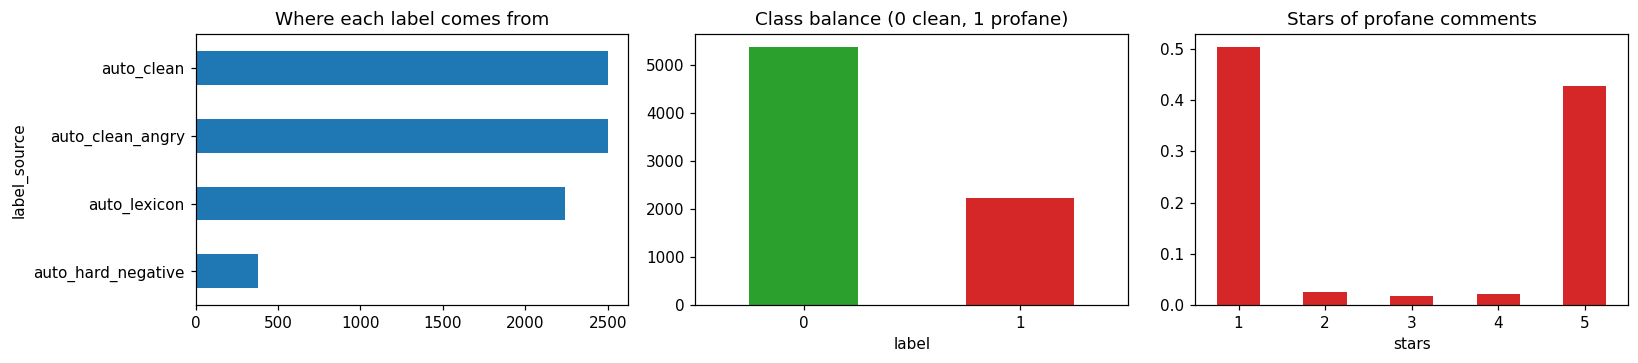

45% of profane comments have 4-5 stars -> sentiment labels can't be reused for this task


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
data.label_source.value_counts().plot.barh(ax=ax[0], title='Where each label comes from'); ax[0].invert_yaxis()
data.label.value_counts().sort_index().plot.bar(ax=ax[1], rot=0, color=['tab:green', 'tab:red'], title='Class balance (0 clean, 1 profane)')
data[data.label == 1].stars.value_counts(normalize=True).sort_index().plot.bar(ax=ax[2], rot=0, color='tab:red',
                                                                              title='Stars of profane comments')
plt.tight_layout(); plt.show()
print(f"{(data[data.label == 1].stars >= 4).mean():.0%} of profane comments have 4-5 stars -> sentiment labels can't be reused for this task")

## 5. Split: train 70% / validation 15% / test 15%
* **Near-duplicates** (the same *set* of words, e.g. `керемет ойын` / `ойын керемет керемет`) form a group, and a whole group goes to one split.
* Stratified by label × (manual or automatic), so every split has the same class balance.
* The **test** split is not touched until section 9.

In [8]:
data['group'] = data.text.map(lambda t: ' '.join(sorted(set(canonical(t).split()))))
g = data.groupby('group').agg(label=('label', 'max'), manual=('label_source', lambda s: (s == 'manual').any()))
strat = g.label.astype(str) + '_' + g.manual.astype(str)
S = CFG['split']
g_train, g_rest = train_test_split(g.index, test_size=S['val'] + S['test'], stratify=strat, random_state=SEED)
g_val, g_test = train_test_split(g_rest, test_size=S['test'] / (S['val'] + S['test']), stratify=strat.loc[g_rest], random_state=SEED)
train, val, test = (data[data.group.isin(set(x))] for x in (g_train, g_val, g_test))

# leakage check: no text / word set may appear in two splits
keys = {n: set(d.text.map(dedupe_key)) | set(d.group) for n, d in [('train', train), ('val', val), ('test', test)]}
assert not (keys['train'] & keys['val'] or keys['train'] & keys['test'] or keys['val'] & keys['test'])
print('leakage check passed: no duplicate or near-duplicate crosses splits')

sizes = pd.DataFrame({n: {'rows': len(d), 'clean (0)': (d.label == 0).sum(), 'profane (1)': (d.label == 1).sum(),
                          'profane %': round(100 * d.label.mean(), 1)} for n, d in [('train', train), ('val', val), ('test', test)]}).T
display(sizes.astype({'rows': int, 'clean (0)': int, 'profane (1)': int}))

leakage check passed: no duplicate or near-duplicate crosses splits


,rows,clean (0),profane (1),profane %
train,5335,3765,1570,29.4
val,1143,806,337,29.5
test,1141,807,334,29.3


## 6. Features: TF-IDF over character n-grams
`char_wb` cuts every word (padded with spaces) into all pieces of 2-5 letters, and TF-IDF weighs them (rare pieces weigh more).
* **Kazakh suffixes:** `котак` is inside `котакбастарга`, so new suffixes still match.
* **Typos and masks** change one or two pieces; the rest still match.
* **Unknown words:** there is no `<UNK>` token, because an unseen word is still made of known pieces.
* **Long comments:** no truncation. The whole comment becomes one vector (L2-normalised).
* **Punctuation** is removed by `canonical()`, except `*` (a mask signal).

The vocabulary is fitted **on the training split only**.

In [9]:
demo_vec = TfidfVectorizer(preprocessor=canonical, analyzer='char_wb', ngram_range=(2, 5), lowercase=False).fit(['Қотақбас сатушы'])
print(len(demo_vec.vocabulary_), 'n-grams for "Қотақбас сатушы", e.g.:', sorted(demo_vec.vocabulary_)[:24])

52 n-grams for "Қотақбас сатушы", e.g.: [' к', ' ко', ' кот', ' кота', ' с', ' са', ' сат', ' сату', 'ак', 'акб', 'акба', 'акбас', 'ас', 'ас ', 'ат', 'ату', 'атуш', 'атушы', 'ба', 'бас', 'бас ', 'кб', 'кба', 'кбас']


## 7. Model and training: Logistic Regression, settings chosen on **validation**
* Model: `TF-IDF → LogisticRegression` (L2-regularised log-loss, `class_weight='balanced'` for the 70/30 imbalance).
* **Augmentation (train only):** copies of 30% of the rows *of each class* with random inner letters replaced by `*`, so the model
  learns that `б*ять` ≈ `блять`. Both classes are masked, so `*` alone does not mean "profane".
* **Grid search:** C × n-gram range. Each model is fitted on train and scored on validation.

In [10]:
def mask_augment(d, frac, seed):
    rng = np.random.default_rng(seed)
    def mask(text):
        words = text.split()
        for i, w in enumerate(words):
            if len(w) >= 4 and w.isalpha() and rng.random() < 0.5:
                j = int(rng.integers(1, len(w) - 1)); words[i] = w[:j] + '*' + w[j + 1:]
        return ' '.join(words)
    extra = d.groupby('label', group_keys=False).sample(frac=frac, random_state=seed).copy()
    extra['text'] = extra.text.map(mask)
    return pd.concat([d, extra], ignore_index=True)

def build_model(C, ngram_range):
    F, K = CFG['model']['features'], CFG['model']['classifier']
    return Pipeline([
        ('tfidf', TfidfVectorizer(preprocessor=canonical, analyzer=F['analyzer'], ngram_range=tuple(ngram_range),
                                  min_df=F['min_df'], sublinear_tf=F['sublinear_tf'], max_features=F['max_features'], lowercase=False)),
        ('clf', LogisticRegression(C=C, class_weight=K['class_weight'], max_iter=K['max_iter'], solver='liblinear', random_state=SEED)),
    ])

def best_f1_threshold(y, proba):
    p, r, t = precision_recall_curve(y, proba)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    i = int(np.argmax(f1)); return float(t[i]), p[i], r[i], f1[i]

train_aug = mask_augment(train, CFG['model']['augment_mask_frac'], SEED)
print(f'train rows: {len(train):,} + {len(train_aug) - len(train):,} masked copies')
rows, best = [], None
for C in CFG['model']['search']['C']:
    for ngr in CFG['model']['search']['ngram_range']:
        model = build_model(C, ngr).fit(train_aug.text, train_aug.label)
        proba = model.predict_proba(val.text)[:, 1]
        thr, p, r, f1 = best_f1_threshold(val.label, proba)
        ap = average_precision_score(val.label, proba)
        rows.append({'C': C, 'ngram_range': str(tuple(ngr)), 'val_F1': f1, 'val_precision': p, 'val_recall': r, 'val_AP': ap, 'threshold': thr})
        if best is None or (round(f1, 4), ap) > best[0]:
            best = ((round(f1, 4), ap), model, C, ngr, thr)
search = pd.DataFrame(rows)
_, model, best_C, best_ngr, THRESHOLD = best
print(f'BEST on validation: C={best_C}, n-grams={tuple(best_ngr)}, threshold={THRESHOLD:.3f}')
search.sort_values('val_F1', ascending=False).head(5).round(4)

train rows: 5,335 + 1,601 masked copies


BEST on validation: C=100.0, n-grams=(2, 5), threshold=0.415


,C,ngram_range,val_F1,val_precision,val_recall,val_AP,threshold
13,100.0,"(2, 5)",0.9851,0.9881,0.9822,0.9984,0.4148
10,30.0,"(2, 5)",0.9822,0.9794,0.9852,0.9983,0.3551
7,10.0,"(2, 5)",0.9822,0.9822,0.9822,0.9981,0.4031
14,100.0,"(3, 6)",0.9806,0.9850,0.9763,0.9979,0.3444
11,30.0,"(3, 6)",0.9792,0.9821,0.9763,0.9976,0.3592


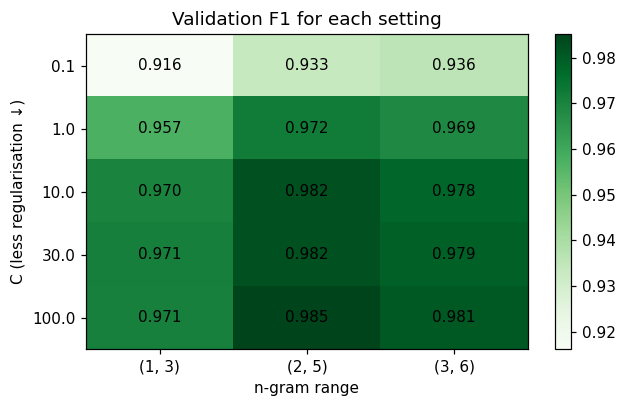

In [11]:
grid = search.pivot(index='C', columns='ngram_range', values='val_F1')
fig, ax = plt.subplots(figsize=(6, 3.8))
im = ax.imshow(grid.values, cmap='Greens', aspect='auto')
ax.set_xticks(range(grid.shape[1]), grid.columns); ax.set_yticks(range(grid.shape[0]), grid.index)
for (i, j), v in np.ndenumerate(grid.values): ax.text(j, i, f'{v:.3f}', ha='center', va='center')
ax.set_xlabel('n-gram range'); ax.set_ylabel('C (less regularisation ↓)'); ax.set_title('Validation F1 for each setting')
plt.colorbar(im); plt.tight_layout(); plt.show()

## 8. Decision threshold (validation)
The model outputs a probability, and the threshold turns it into 0/1. 0.5 is not automatically best for imbalanced data,
so we pick the threshold with the highest F1 **on validation**.

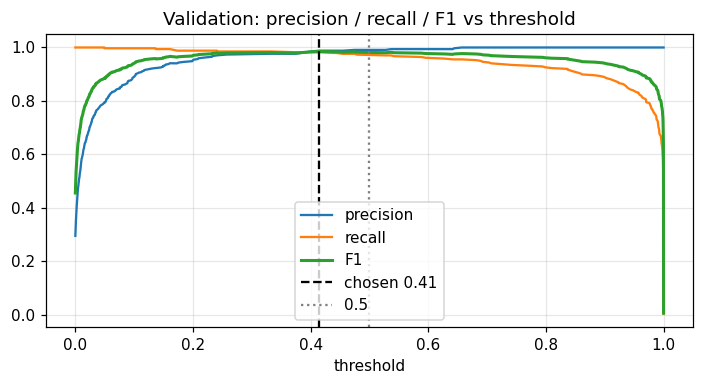

In [12]:
val_proba = model.predict_proba(val.text)[:, 1]
p, r, t = precision_recall_curve(val.label, val_proba)
f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
plt.figure(figsize=(6.5, 3.6))
plt.plot(t, p[:-1], label='precision'); plt.plot(t, r[:-1], label='recall'); plt.plot(t, f1[:-1], label='F1', lw=2)
plt.axvline(THRESHOLD, color='k', ls='--', label=f'chosen {THRESHOLD:.2f}'); plt.axvline(0.5, color='grey', ls=':', label='0.5')
plt.xlabel('threshold'); plt.title('Validation: precision / recall / F1 vs threshold'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 9. Test: evaluated **once** with the chosen model and threshold

In [13]:
test_proba = model.predict_proba(test.text)[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)
y = test.label.values

def scores(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average='binary', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'precision': p, 'recall': r, 'F1': f, 'accuracy': accuracy_score(y, pred), 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}

results = pd.DataFrame({'model': scores(y, test_pred),
                        'lexicon only': scores(y, test.text.map(predict_lexicon).values),
                        'always 0': scores(y, np.zeros_like(y))}).T
print(f'test examples: {len(test)} ({y.sum()} profane) | threshold {THRESHOLD:.3f} | '
      f'ROC-AUC {roc_auc_score(y, test_proba):.4f} | AP {average_precision_score(y, test_proba):.4f}')
display(results.astype(float).round(3))
print(classification_report(y, test_pred, target_names=['clean (0)', 'profane (1)'], digits=3))

test examples: 1141 (334 profane) | threshold 0.415 | ROC-AUC 0.9980 | AP 0.9968


,precision,recall,F1,accuracy,TP,FP,FN,TN
model,0.997,0.958,0.977,0.987,320.0,1.0,14.0,806.0
lexicon only,1.000,1.000,1.000,1.000,334.0,0.0,0.0,807.0
always 0,0.000,0.000,0.000,0.707,0.0,0.0,334.0,807.0


              precision    recall  f1-score   support

   clean (0)      0.983     0.999     0.991       807
 profane (1)      0.997     0.958     0.977       334

    accuracy                          0.987      1141
   macro avg      0.990     0.978     0.984      1141
weighted avg      0.987     0.987     0.987      1141



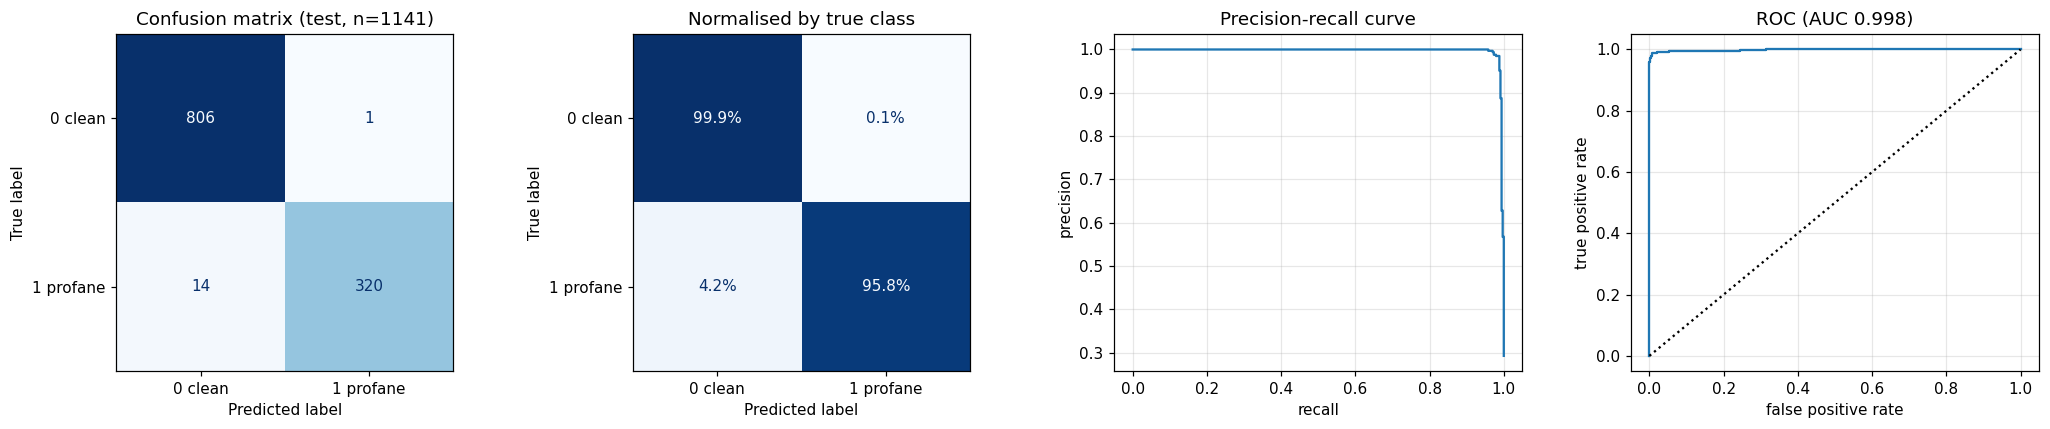

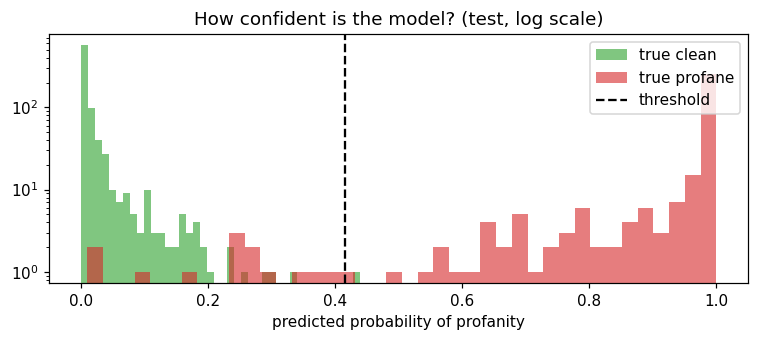

In [14]:
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
ConfusionMatrixDisplay(confusion_matrix(y, test_pred), display_labels=['0 clean', '1 profane']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title(f'Confusion matrix (test, n={len(test)})')
ConfusionMatrixDisplay(confusion_matrix(y, test_pred, normalize='true'), display_labels=['0 clean', '1 profane']).plot(
    ax=ax[1], cmap='Blues', colorbar=False, values_format='.1%'); ax[1].set_title('Normalised by true class')
pr_p, pr_r, _ = precision_recall_curve(y, test_proba)
ax[2].plot(pr_r, pr_p); ax[2].set_xlabel('recall'); ax[2].set_ylabel('precision'); ax[2].set_title('Precision-recall curve'); ax[2].grid(alpha=.3)
fpr, tpr, _ = roc_curve(y, test_proba)
ax[3].plot(fpr, tpr); ax[3].plot([0, 1], [0, 1], 'k:'); ax[3].set_xlabel('false positive rate'); ax[3].set_ylabel('true positive rate')
ax[3].set_title(f'ROC (AUC {roc_auc_score(y, test_proba):.3f})'); ax[3].grid(alpha=.3)
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 3.2))
plt.hist(test_proba[y == 0], bins=40, alpha=.6, label='true clean', color='tab:green', log=True)
plt.hist(test_proba[y == 1], bins=40, alpha=.6, label='true profane', color='tab:red', log=True)
plt.axvline(THRESHOLD, color='k', ls='--', label='threshold'); plt.xlabel('predicted probability of profanity')
plt.title('How confident is the model? (test, log scale)'); plt.legend(); plt.tight_layout(); plt.show()

**Reading the results**
* **precision** = TP/(TP+FP): of the flagged comments, how many were really profane. **recall** = TP/(TP+FN): of the profane comments, how many were caught.
* **FP** = a clean (maybe angry) review gets hidden, which is unfair to the customer. **FN** = мат is published, which hurts the platform.
  For moderation, FN is usually worse, so a lower threshold or a "send to a human" band is reasonable.
* Accuracy is misleading: "always 0" already gets ~70%.
* "Lexicon only" scores 1.0 because most test labels **were made by the lexicon** (circular). The challenge set (section 12) and the error analysis show what the model learned beyond it.

## 10. What did the model learn?

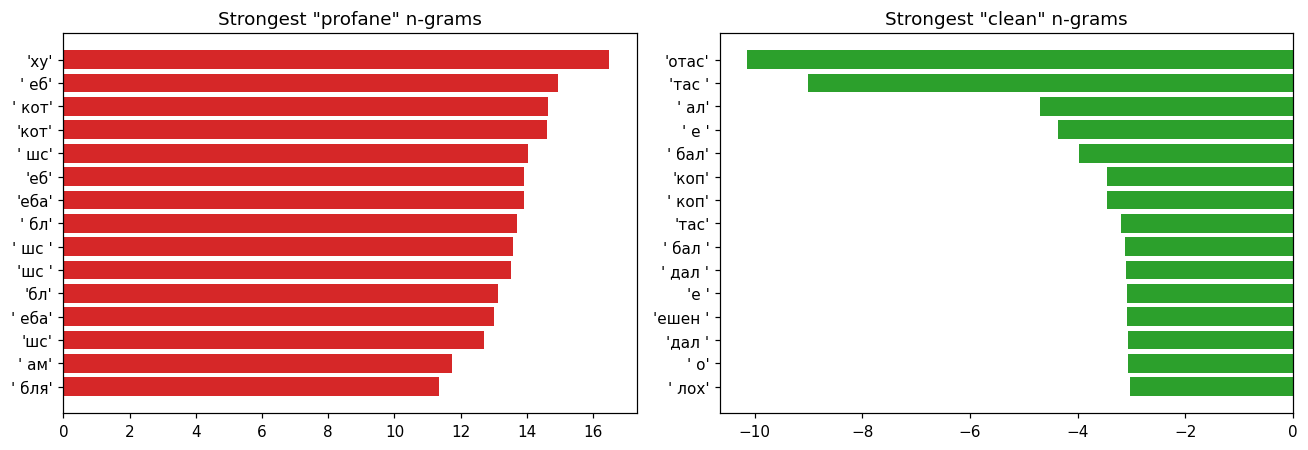

In [15]:
vec, clf = model.named_steps['tfidf'], model.named_steps['clf']
names, coef = vec.get_feature_names_out(), clf.coef_[0]
order = np.argsort(coef)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].barh([repr(names[i]) for i in order[::-1][:15]][::-1], coef[order[::-1][:15]][::-1], color='tab:red'); ax[0].set_title('Strongest "profane" n-grams')
ax[1].barh([repr(names[i]) for i in order[:15]][::-1], coef[order[:15]][::-1], color='tab:green'); ax[1].set_title('Strongest "clean" n-grams')
plt.tight_layout(); plt.show()

raw: 'сатушы далбайоп'
canonical: 'сатушы далбайоп'
51 active n-grams | logit = -5.73 + 12.26 = 6.54 | p = 0.9986 | label = 1


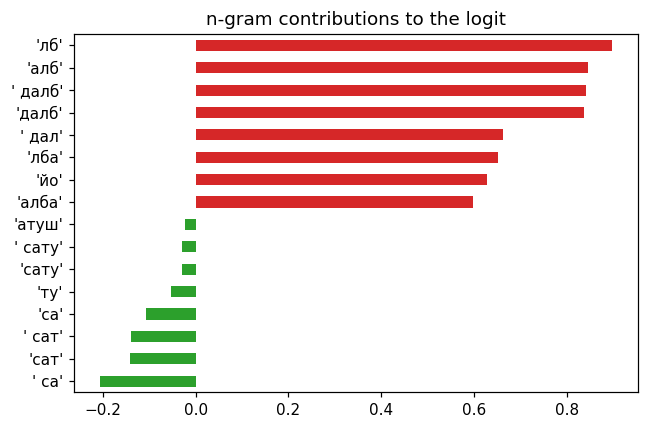

In [16]:
def trace(text, top=8):
    """raw text -> canonical -> n-grams -> sum(tfidf * weight) + intercept = logit -> sigmoid -> threshold -> label"""
    x = vec.transform([text]); idx = x.indices; contrib = x.data * coef[idx]
    logit = contrib.sum() + clf.intercept_[0]; prob = 1 / (1 + np.exp(-logit))
    print(f'raw: {text!r}\ncanonical: {canonical(text)!r}\n{len(idx)} active n-grams | '
          f'logit = {clf.intercept_[0]:.2f} + {contrib.sum():.2f} = {logit:.2f} | p = {prob:.4f} | label = {int(prob >= THRESHOLD)}')
    o = np.argsort(contrib); sel = np.r_[o[:top], o[::-1][:top]]
    s = pd.Series(contrib[sel], index=[repr(names[idx[i]]) for i in sel]).sort_values()
    s.plot.barh(figsize=(6, 4), color=np.where(s > 0, 'tab:red', 'tab:green'), title='n-gram contributions to the logit'); plt.tight_layout(); plt.show()

trace('сатушы далбайоп')

## 11. Errors (counts only; the texts are in `results/errors.csv`, created locally)

,n,median_words,mean_probability
outcome,,,
FN (missed мат),14,12.5,0.24
FP (clean flagged),1,4.0,0.44
TN,806,6.0,0.02
TP,320,6.0,0.96


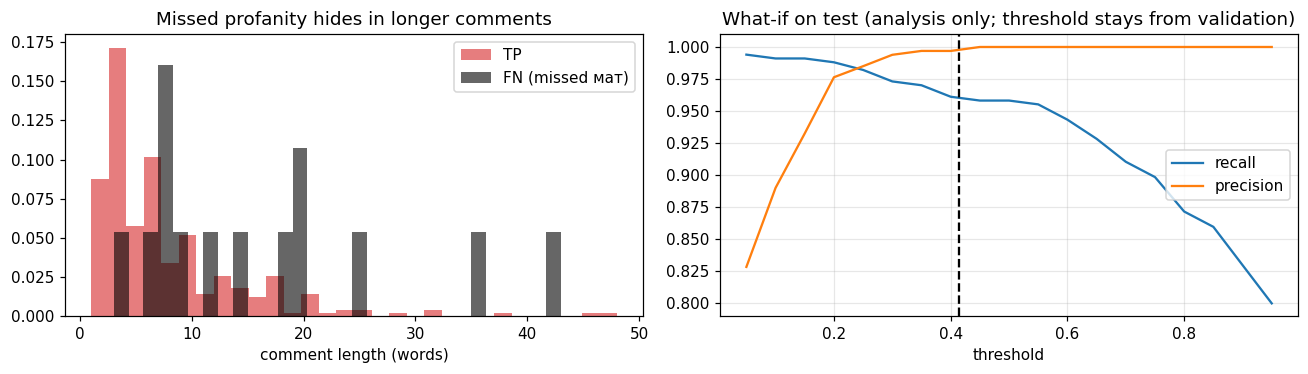

In [17]:
out = test.assign(proba=test_proba, pred=test_pred, words=test.text.str.split().str.len())
out['outcome'] = np.select([(out.label == 1) & (out.pred == 1), (out.label == 1) & (out.pred == 0), (out.label == 0) & (out.pred == 1)],
                           ['TP', 'FN (missed мат)', 'FP (clean flagged)'], 'TN')
display(out.groupby('outcome').agg(n=('id', 'size'), median_words=('words', 'median'), mean_probability=('proba', 'mean')).round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for o, c in [('TP', 'tab:red'), ('FN (missed мат)', 'k')]:
    ax[0].hist(out[out.outcome == o].words.clip(upper=60), bins=30, alpha=.6, density=True, label=o, color=c)
ax[0].set_xlabel('comment length (words)'); ax[0].set_title('Missed profanity hides in longer comments'); ax[0].legend()
ths = np.linspace(0.05, 0.95, 19)
ax[1].plot(ths, [precision_recall_fscore_support(y, (test_proba >= t).astype(int), average='binary', zero_division=0)[1] for t in ths], label='recall')
ax[1].plot(ths, [precision_recall_fscore_support(y, (test_proba >= t).astype(int), average='binary', zero_division=0)[0] for t in ths], label='precision')
ax[1].axvline(THRESHOLD, color='k', ls='--'); ax[1].set_xlabel('threshold'); ax[1].legend(); ax[1].grid(alpha=.3)
ax[1].set_title('What-if on test (analysis only; threshold stays from validation)')
plt.tight_layout(); plt.show()

## 12. Challenge set: 40 hand-written sentences (synthetic, never used for training)
Tests what lexicon-made labels cannot: masks, spaced letters, new spellings, insults and innocent look-alikes.

In [18]:
ch = pd.read_csv(CFG['paths']['challenge_file'])
ch['proba'] = model.predict_proba(ch.text)[:, 1].round(3); ch['pred'] = (ch.proba >= THRESHOLD).astype(int)
ch['lexicon'] = ch.text.map(predict_lexicon)
print('model  :', {k: round(v, 3) for k, v in scores(ch.label, ch.pred).items() if k in ('precision', 'recall', 'F1')})
print('lexicon:', {k: round(v, 3) for k, v in scores(ch.label, ch.lexicon).items() if k in ('precision', 'recall', 'F1')})
display(ch.groupby('category')[['label']].size().to_frame('n').join(
    ch.assign(model_ok=ch.pred == ch.label, lexicon_ok=ch.lexicon == ch.label).groupby('category')[['model_ok', 'lexicon_ok']].sum()))
ch[ch.pred != ch.label][['text', 'label', 'proba', 'category']]

model  : {'precision': 1.0, 'recall': 0.7, 'F1': 0.824}
lexicon: {'precision': 1.0, 'recall': 0.85, 'F1': 0.919}


,n,model_ok,lexicon_ok
category,,,
angry_clean,2,2,2
insult_not_profanity,3,3,3
kazakh_phrase,2,2,2
kazakh_word,2,0,2
latin_translit,1,1,1
lookalike,15,15,15
masked,4,2,3
russian_in_kazakh,3,3,3
spaced_letters,1,1,1


,text,label,proba,category
3,Сатушы б**ть телефонды сындырып жіберді,1,0.033,masked
5,Тауар х*йня екен ақша босқа,1,0.045,masked
12,Блиаать тағы да сынық келді,1,0.366,spelling_variant
13,Зайыбал тауар бір күнде сынды,1,0.124,unseen_variant
18,Қаншықтар тауарды ауыстырмайды,1,0.069,kazakh_word
19,Жәлептер ғана сатып алады мұны,1,0.166,kazakh_word


## 13. Save the model
One file holds the fitted TF-IDF vocabulary, the classifier, the threshold and the settings, so prediction needs no retraining.

In [19]:
Path('models').mkdir(exist_ok=True)
F = dict(CFG['model']['features'], ngram_range=list(best_ngr)); K = dict(CFG['model']['classifier'], C=best_C)
joblib.dump({'pipeline': model, 'threshold': THRESHOLD, 'features': F, 'classifier': K, 'seed': SEED,
             'trained_on_rows': len(train_aug), 'augment_mask_frac': CFG['model']['augment_mask_frac'],
             'package_version': '1.0.0'}, 'models/model.joblib', compress=3)
print(f"saved models/model.joblib ({Path('models/model.joblib').stat().st_size / 1e6:.1f} MB)")

saved models/model.joblib (0.6 MB)


## 14. Predict your own comments (loads the saved model, no retraining)

In [20]:
bundle = joblib.load('models/model.joblib')
def predict(text):
    p = bundle['pipeline'].predict_proba([text])[0, 1]
    return {'text': text, 'label': int(p >= bundle['threshold']), 'probability': round(float(p), 4)}

pd.DataFrame([predict(t) for t in ['Тауар өте нашар, ақша босқа кетті', 'Курьер ақымақ екен', 'Қ*тақ бас сатушы', 'Керемет сапа, рахмет!']])

,text,label,probability
0,"Тауар өте нашар, ақша босқа кетті",0,0.0013
1,Курьер ақымақ екен,0,0.0001
2,Қ*тақ бас сатушы,1,0.9820
3,"Керемет сапа, рахмет!",0,0.0011


In [21]:
# Type your own comment (uncomment in Jupyter/Colab):
# print(predict(input('Comment: ')))
# trace(input('Comment to trace: '))

In [22]:
# Reproducibility check: the same pipeline also exists as scripts (python -m kzprofanity.train / evaluate).
if Path('results/metrics.json').exists():
    m = json.load(open('results/metrics.json'))['test']
    same = (m['tp'], m['fp'], m['fn'], m['tn']) == tuple(int(results.loc['model', k]) for k in ('TP', 'FP', 'FN', 'TN'))
    print('notebook confusion matrix == scripts confusion matrix:', same)

notebook confusion matrix == scripts confusion matrix: True
